# 02 — Preprocessing & Windowing V2  
## Exact 8-Second Windows, No Saving

This notebook prepares the duplicated raw recordings for Deep Learning while keeping the supervisor's latest instruction in mind.

### What stays unchanged
- duplicated raw samples are **not removed**
- no signal interpolation
- no filtering
- no normalization
- no processed dataset is saved to disk

### What is corrected in this version
The previous version used a fixed number of stored rows per window. Because the stored row rate varies, 321 rows sometimes represented about 6.7 s and sometimes more than 11 s.

This version instead:

1. creates windows from the **real `Timestamp_ms` values**
2. every model window represents exactly **8.0 seconds**
3. creates a fixed model input length of **320 points**
4. does **not interpolate signal values**
5. for each desired time point, selects the nearest existing recorded row
6. uses the mean chest-strap HR inside the same 8-second interval as the regression target

Therefore both the PPG-only and PPG+ACC models receive inputs with the same temporal duration and the same number of points.

> The fixed 320-point representation is only an in-memory model input preparation step. The original Excel files are not modified.

## 1. Imports

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

## 2. Configuration

In [2]:
WINDOW_SECONDS = 8.0
WINDOW_MS = int(WINDOW_SECONDS * 1000)

MODEL_POINTS = 320
MAX_ALLOWED_TIME_ERROR_MS = 100.0

TRAIN_RATIO = 0.70
VAL_RATIO = 0.15
TEST_RATIO = 0.15

ACTIVITY_ORDER = [
    "Eating",
    "High_Tempo_Cycling",
    "Low_Tempo_Cycling",
    "Sitting",
    "Sleep",
    "Walking",
]

MODEL_INPUT_COLUMNS = [
    "PPG_Raw",
    "ACC_X",
    "ACC_Y",
    "ACC_Z",
]

TARGET_COLUMN = "Chest_HR_BPM"

print(f"Exact window duration : {WINDOW_SECONDS:.1f} s")
print(f"Model points/window   : {MODEL_POINTS}")
print(f"Nominal model spacing : {WINDOW_SECONDS / MODEL_POINTS * 1000:.1f} ms")
print(f"Max allowed timing err: {MAX_ALLOWED_TIME_ERROR_MS:.0f} ms")
print(f"Split                 : {TRAIN_RATIO:.0%} / {VAL_RATIO:.0%} / {TEST_RATIO:.0%}")

Exact window duration : 8.0 s
Model points/window   : 320
Nominal model spacing : 25.0 ms
Max allowed timing err: 100 ms
Split                 : 70% / 15% / 15%


## 3. Project Paths & Session Discovery

In [3]:
PROJECT_ROOT = Path("..").resolve()
DATA_ROOT = PROJECT_ROOT / "data" / "raw"

ACTIVITY_DIRS = {
    "Eating": DATA_ROOT / "eating",
    "High_Tempo_Cycling": DATA_ROOT / "high_tempo_cycling",
    "Low_Tempo_Cycling": DATA_ROOT / "low_tempo_cycling",
    "Sitting": DATA_ROOT / "sitting",
    "Sleep": DATA_ROOT / "sleep",
    "Walking": DATA_ROOT / "walking",
}


def discover_activity_files(activity, folder):
    files = sorted(folder.glob("*.xlsx"))

    # Use corrected session-split files when present.
    if activity == "Sitting":
        split_files = sorted(folder.glob("Sitting_*.xlsx"))
        if split_files:
            return split_files

    if activity == "Walking":
        split_files = sorted(folder.glob("Walking_*.xlsx"))
        if split_files:
            return split_files

    return files


records = []

for activity in ACTIVITY_ORDER:
    files = discover_activity_files(
        activity,
        ACTIVITY_DIRS[activity]
    )

    if not files:
        raise FileNotFoundError(
            f"No Excel file found for {activity}: {ACTIVITY_DIRS[activity]}"
        )

    for i, path in enumerate(files, start=1):
        records.append({
            "Activity": activity,
            "Session_ID": f"{activity}_{i:02d}",
            "File_Path": path,
            "File_Name": path.name,
        })


session_index = pd.DataFrame(records)

display(
    session_index[
        ["Activity", "Session_ID", "File_Name"]
    ]
)

,Activity,Session_ID,File_Name
0,Eating,Eating_01,PPG_IMU_Chest_Eating.xlsx
1,High_Tempo_Cycling,High_Tempo_Cycling_01,PPG_IMU_Chest_High_Tempo_Cycling.xlsx
2,Low_Tempo_Cycling,Low_Tempo_Cycling_01,PPG_IMU_Chest_Low_Tempo_Cycling.xlsx
3,Sitting,Sitting_01,Sitting_01.xlsx
4,Sitting,Sitting_02,Sitting_02.xlsx
5,Sleep,Sleep_01,PPG_IMU_Chest_Sleep.xlsx
6,Walking,Walking_01,Walking_01.xlsx
7,Walking,Walking_02,Walking_02.xlsx


## 4. Load Raw Sessions

In [4]:
NUMERIC_COLUMNS = [
    "Timestamp_ms",
    "PPG_Raw",
    "ACC_X",
    "ACC_Y",
    "ACC_Z",
    "Chest_HR_BPM",
]


def load_session(path):
    df = pd.read_excel(path)

    missing = (
        set(NUMERIC_COLUMNS)
        - set(df.columns)
    )

    if missing:
        raise ValueError(
            f"{path.name} is missing: {sorted(missing)}"
        )

    for col in NUMERIC_COLUMNS:
        df[col] = pd.to_numeric(
            df[col],
            errors="coerce"
        )

    # Keep duplicated timestamps and values.
    # Sort only if timestamp order is not monotonic.
    if not df["Timestamp_ms"].dropna().is_monotonic_increasing:
        print(
            f"Warning: {path.name} was not timestamp-sorted. "
            "Using stable in-memory timestamp sorting."
        )

        df = (
            df.sort_values(
                "Timestamp_ms",
                kind="stable"
            )
            .reset_index(drop=True)
        )

    return df


sessions = {}

for row in session_index.itertuples(index=False):
    df = load_session(row.File_Path)

    sessions[row.Session_ID] = {
        "activity": row.Activity,
        "file_name": row.File_Name,
        "data": df,
    }

    ts = df["Timestamp_ms"].dropna()

    duration_min = (
        (ts.max() - ts.min()) / 60000.0
        if len(ts) >= 2
        else np.nan
    )

    print(
        f"{row.Session_ID:28s} | "
        f"{len(df):>8,} rows | "
        f"{duration_min:>7.2f} min"
    )

Eating_01                    |   15,399 rows |    6.52 min
High_Tempo_Cycling_01        |   78,804 rows |   32.76 min
Low_Tempo_Cycling_01         |  117,724 rows |   48.94 min
Sitting_01                   |   82,213 rows |   34.02 min
Sitting_02                   |    6,252 rows |    2.63 min
Sleep_01                     |  156,017 rows |   64.38 min
Walking_01                   |   61,751 rows |   25.55 min
Walking_02                   |   95,929 rows |   40.11 min


## 5. Raw Data Timing Overview

This section is diagnostic only.

The duplicated rows remain in the data.  
We report the stored row density so we can see why a fixed-row window was not reliable in the previous notebook.

In [5]:
timing_rows = []

for session_id, item in sessions.items():
    df = item["data"]
    ts = df["Timestamp_ms"].dropna()

    if len(ts) >= 2:
        duration_sec = (
            ts.max() - ts.min()
        ) / 1000.0

        stored_row_rate = (
            len(df) / duration_sec
            if duration_sec > 0
            else np.nan
        )
    else:
        duration_sec = np.nan
        stored_row_rate = np.nan

    timing_rows.append({
        "Activity": item["activity"],
        "Session_ID": session_id,
        "Rows": len(df),
        "Duration_min": duration_sec / 60.0,
        "Stored_Row_Rate_Hz": stored_row_rate,
        "Repeated_Timestamp_%": (
            df["Timestamp_ms"].duplicated().mean()
            * 100
        ),
    })


timing_df = pd.DataFrame(
    timing_rows
)

display(
    timing_df.round(3)
)

,Activity,Session_ID,Rows,Duration_min,Stored_Row_Rate_Hz,Repeated_Timestamp_%
0,Eating,Eating_01,15399,6.518,39.376,0.0
1,High_Tempo_Cycling,High_Tempo_Cycling_01,78804,32.761,40.091,0.0
2,Low_Tempo_Cycling,Low_Tempo_Cycling_01,117724,48.943,40.089,0.0
3,Sitting,Sitting_01,82213,34.016,40.281,0.0
4,Sitting,Sitting_02,6252,2.625,39.695,0.0
5,Sleep,Sleep_01,156017,64.379,40.391,0.0
6,Walking,Walking_01,61751,25.546,40.287,0.0
7,Walking,Walking_02,95929,40.108,39.863,0.0


## 6. Nearest-Recorded-Row Selection

For every exact 8-second time interval we create 320 desired time positions.

Example:

`0 ms, 25 ms, 50 ms, ...`

For each desired position, the nearest **existing recorded row** inside that same 8-second window is selected.

No PPG or accelerometer value is mathematically interpolated.

Because the original logger stored rows densely, this produces a fixed input shape while keeping the model window duration physically consistent.

**Timing quality control:** a window is rejected if any selected sample is more than **100 ms** away from its desired time position. This removes windows with large internal timing gaps without changing the duplicated raw recordings.


In [6]:
def nearest_row_indices(
    timestamps,
    desired_times
):
    timestamps = np.asarray(
        timestamps,
        dtype=np.float64
    )

    desired_times = np.asarray(
        desired_times,
        dtype=np.float64
    )

    positions = np.searchsorted(
        timestamps,
        desired_times,
        side="left"
    )

    positions = np.clip(
        positions,
        0,
        len(timestamps) - 1
    )

    previous = np.clip(
        positions - 1,
        0,
        len(timestamps) - 1
    )

    next_dist = np.abs(
        timestamps[positions]
        - desired_times
    )

    prev_dist = np.abs(
        timestamps[previous]
        - desired_times
    )

    choose_previous = (
        prev_dist <= next_dist
    )

    nearest = positions.copy()

    nearest[
        choose_previous
    ] = previous[
        choose_previous
    ]

    return nearest

## 7. Build Exact 8-Second Windows

In [7]:
def build_exact_windows(
    df,
    activity,
    session_id,
):
    clean_ts_mask = (
        df["Timestamp_ms"]
        .notna()
    )

    work = (
        df.loc[clean_ts_mask]
        .copy()
        .reset_index(drop=True)
    )

    timestamps = (
        work["Timestamp_ms"]
        .to_numpy(dtype=np.float64)
    )

    if len(timestamps) < 2:
        return None

    session_start = float(
        timestamps[0]
    )

    session_end = float(
        timestamps[-1]
    )

    n_candidate_windows = int(
        np.floor(
            (session_end - session_start)
            / WINDOW_MS
        )
    )

    X_ppg = []
    X_fusion = []
    y = []
    metadata = []

    rejected_no_rows = 0
    rejected_input = 0
    rejected_target = 0
    rejected_timing = 0

    for window_id in range(
        n_candidate_windows
    ):
        start_ms = (
            session_start
            + window_id * WINDOW_MS
        )

        end_ms = (
            start_ms
            + WINDOW_MS
        )

        left = np.searchsorted(
            timestamps,
            start_ms,
            side="left"
        )

        right = np.searchsorted(
            timestamps,
            end_ms,
            side="left"
        )

        if right <= left:
            rejected_no_rows += 1
            continue

        w = work.iloc[
            left:right
        ].copy()

        local_ts = (
            w["Timestamp_ms"]
            .to_numpy(dtype=np.float64)
        )

        if len(local_ts) < 2:
            rejected_no_rows += 1
            continue

        desired_times = np.linspace(
            start_ms,
            end_ms,
            MODEL_POINTS,
            endpoint=False,
            dtype=np.float64
        )

        selected_local_idx = (
            nearest_row_indices(
                local_ts,
                desired_times
            )
        )

        selected = (
            w.iloc[
                selected_local_idx
            ]
        )

        model_values = (
            selected[
                MODEL_INPUT_COLUMNS
            ]
            .to_numpy(
                dtype=np.float32
            )
        )

        if not np.isfinite(
            model_values
        ).all():
            rejected_input += 1
            continue

        target_values = (
            w[TARGET_COLUMN]
            .dropna()
            .to_numpy(
                dtype=np.float32
            )
        )

        if len(target_values) == 0:
            rejected_target += 1
            continue

        target_hr = float(
            np.mean(
                target_values
            )
        )

        selected_ts = (
            selected["Timestamp_ms"]
            .to_numpy(
                dtype=np.float64
            )
        )

        timing_error_ms = np.abs(
            selected_ts
            - desired_times
        )

        # Timing QC: reject only windows with a large internal gap.
        # The original duplicated rows are not removed or modified.
        if float(np.max(timing_error_ms)) > MAX_ALLOWED_TIME_ERROR_MS:
            rejected_timing += 1
            continue

        X_ppg.append(
            model_values[:, 0:1]
        )

        X_fusion.append(
            model_values
        )

        y.append(
            target_hr
        )

        metadata.append({
            "Activity": activity,
            "Session_ID": session_id,
            "Window_ID": window_id,
            "Window_Start_ms": start_ms,
            "Window_End_ms": end_ms,
            "Window_Duration_sec": WINDOW_SECONDS,
            "Raw_Rows_in_Window": len(w),
            "Unique_Selected_Rows": len(
                np.unique(
                    selected_local_idx
                )
            ),
            "Mean_Time_Error_ms": float(
                np.mean(
                    timing_error_ms
                )
            ),
            "Max_Time_Error_ms": float(
                np.max(
                    timing_error_ms
                )
            ),
            "Chest_Samples": len(
                target_values
            ),
            "Target_HR_BPM": target_hr,
        })

    return {
        "X_ppg": np.asarray(
            X_ppg,
            dtype=np.float32
        ),
        "X_fusion": np.asarray(
            X_fusion,
            dtype=np.float32
        ),
        "y": np.asarray(
            y,
            dtype=np.float32
        ),
        "metadata": pd.DataFrame(
            metadata
        ),
        "candidate_windows": n_candidate_windows,
        "rejected_no_rows": rejected_no_rows,
        "rejected_input": rejected_input,
        "rejected_target": rejected_target,
        "rejected_timing": rejected_timing,
    }

## 8. Process All Sessions

In [8]:
windowed_sessions = {}

summary_rows = []

for session_id, item in sessions.items():
    result = build_exact_windows(
        df=item["data"],
        activity=item["activity"],
        session_id=session_id,
    )

    if result is None:
        print(
            f"Skipped {session_id}"
        )
        continue

    windowed_sessions[
        session_id
    ] = result

    summary_rows.append({
        "Activity": item["activity"],
        "Session_ID": session_id,
        "Candidate_Windows": result[
            "candidate_windows"
        ],
        "Valid_Windows": len(
            result["y"]
        ),
        "Rejected_No_Rows": result[
            "rejected_no_rows"
        ],
        "Rejected_Input": result[
            "rejected_input"
        ],
        "Rejected_Target": result[
            "rejected_target"
        ],
        "Rejected_Timing": result[
            "rejected_timing"
        ],
    })


window_summary_df = pd.DataFrame(
    summary_rows
)

display(
    window_summary_df
)

,Activity,Session_ID,Candidate_Windows,Valid_Windows,Rejected_No_Rows,Rejected_Input,Rejected_Target,Rejected_Timing
0,Eating,Eating_01,48,48,0,0,0,0
1,High_Tempo_Cycling,High_Tempo_Cycling_01,245,245,0,0,0,0
2,Low_Tempo_Cycling,Low_Tempo_Cycling_01,367,365,0,0,1,1
3,Sitting,Sitting_01,255,255,0,0,0,0
4,Sitting,Sitting_02,19,19,0,0,0,0
5,Sleep,Sleep_01,482,482,0,0,0,0
6,Walking,Walking_01,191,187,0,0,1,3
7,Walking,Walking_02,300,294,0,0,0,6


## 9. Verify Window Duration & Time Alignment

All accepted model windows are exactly 8.0 seconds by definition.

The important diagnostic here is now the **nearest-row timing error**, not window duration variability.

In [9]:
all_metadata = pd.concat(
    [
        result["metadata"]
        for result in windowed_sessions.values()
        if len(
            result["metadata"]
        )
    ],
    ignore_index=True
)

alignment_summary = (
    all_metadata
    .groupby(
        "Activity"
    )
    .agg(
        Windows=(
            "Window_ID",
            "count"
        ),
        Mean_Raw_Rows=(
            "Raw_Rows_in_Window",
            "mean"
        ),
        Mean_Unique_Selected_Rows=(
            "Unique_Selected_Rows",
            "mean"
        ),
        Mean_Time_Error_ms=(
            "Mean_Time_Error_ms",
            "mean"
        ),
        Worst_Time_Error_ms=(
            "Max_Time_Error_ms",
            "max"
        ),
    )
)

display(
    alignment_summary.round(3)
)

,Windows,Mean_Raw_Rows,Mean_Unique_Selected_Rows,Mean_Time_Error_ms,Worst_Time_Error_ms
Activity,,,,,
Eating,48,316.812,279.646,7.235,66.0
High_Tempo_Cycling,245,320.996,282.478,6.986,68.0
Low_Tempo_Cycling,365,320.666,281.493,7.115,86.0
Sitting,274,321.938,281.270,7.072,54.0
Sleep,482,323.095,282.309,6.985,76.0
Walking,481,320.235,281.125,7.115,98.0


## 10. Timing Error Distribution

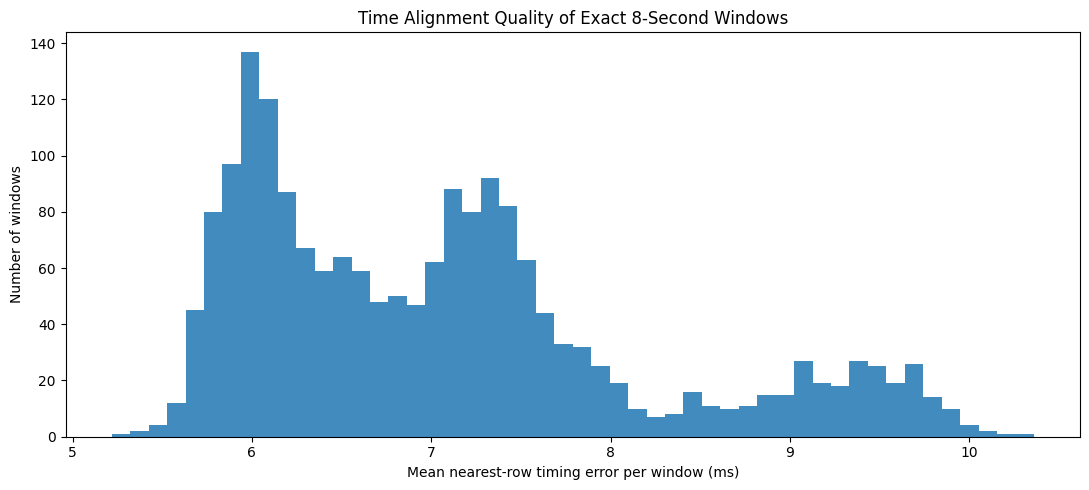

In [10]:
plt.figure(
    figsize=(11, 5)
)

plt.hist(
    all_metadata[
        "Mean_Time_Error_ms"
    ],
    bins=50,
    alpha=0.85
)

plt.xlabel(
    "Mean nearest-row timing error per window (ms)"
)

plt.ylabel(
    "Number of windows"
)

plt.title(
    "Time Alignment Quality of Exact 8-Second Windows"
)

plt.tight_layout()
plt.show()

## 11. Chronological Train / Validation / Test Split

The split is performed separately inside every recording session:

- first 70% → Train
- next 15% → Validation
- final 15% → Test

No window is randomly shuffled before splitting.

PPG-only and PPG+ACC use the **same windows, same target values, and same split**.

In [11]:
def chronological_split_indices(
    n_windows
):
    n_train = int(
        np.floor(
            n_windows
            * TRAIN_RATIO
        )
    )

    n_val = int(
        np.floor(
            n_windows
            * VAL_RATIO
        )
    )

    n_test = (
        n_windows
        - n_train
        - n_val
    )

    train_idx = np.arange(
        0,
        n_train
    )

    val_idx = np.arange(
        n_train,
        n_train + n_val
    )

    test_idx = np.arange(
        n_train + n_val,
        n_windows
    )

    return (
        train_idx,
        val_idx,
        test_idx,
    )

## 12. Apply Split

In [12]:
split_storage = {
    "train": {
        "X_ppg": [],
        "X_fusion": [],
        "y": [],
        "meta": [],
    },
    "val": {
        "X_ppg": [],
        "X_fusion": [],
        "y": [],
        "meta": [],
    },
    "test": {
        "X_ppg": [],
        "X_fusion": [],
        "y": [],
        "meta": [],
    },
}


for session_id, result in windowed_sessions.items():
    n = len(
        result["y"]
    )

    (
        train_idx,
        val_idx,
        test_idx,
    ) = chronological_split_indices(
        n
    )

    split_indices = {
        "train": train_idx,
        "val": val_idx,
        "test": test_idx,
    }

    for split_name, idx in split_indices.items():
        if len(idx) == 0:
            continue

        split_storage[
            split_name
        ]["X_ppg"].append(
            result["X_ppg"][idx]
        )

        split_storage[
            split_name
        ]["X_fusion"].append(
            result["X_fusion"][idx]
        )

        split_storage[
            split_name
        ]["y"].append(
            result["y"][idx]
        )

        meta = (
            result["metadata"]
            .iloc[idx]
            .copy()
        )

        meta["Split"] = (
            split_name
        )

        split_storage[
            split_name
        ]["meta"].append(
            meta
        )

## 13. Concatenate Final In-Memory Arrays

In [13]:
def concatenate_split(
    storage
):
    return (
        np.concatenate(
            storage["X_ppg"],
            axis=0
        ),
        np.concatenate(
            storage["X_fusion"],
            axis=0
        ),
        np.concatenate(
            storage["y"],
            axis=0
        ),
        pd.concat(
            storage["meta"],
            ignore_index=True
        ),
    )


(
    X_ppg_train,
    X_fusion_train,
    y_train,
    meta_train,
) = concatenate_split(
    split_storage["train"]
)


(
    X_ppg_val,
    X_fusion_val,
    y_val,
    meta_val,
) = concatenate_split(
    split_storage["val"]
)


(
    X_ppg_test,
    X_fusion_test,
    y_test,
    meta_test,
) = concatenate_split(
    split_storage["test"]
)

## 14. Final Shapes

In [15]:
print("PPG-only")
print("--------")
print(
    "Train:",
    X_ppg_train.shape,
    y_train.shape
)
print(
    "Val  :",
    X_ppg_val.shape,
    y_val.shape
)
print(
    "Test :",
    X_ppg_test.shape,
    y_test.shape
)

print()

print("PPG + ACC")
print("---------")
print(
    "Train:",
    X_fusion_train.shape,
    y_train.shape
)
print(
    "Val  :",
    X_fusion_val.shape,
    y_val.shape
)
print(
    "Test :",
    X_fusion_test.shape,
    y_test.shape
)

assert (
    X_ppg_train.shape[1:]
    == (MODEL_POINTS, 1)
)

assert (
    X_fusion_train.shape[1:]
    == (MODEL_POINTS, 4)
)

print()
print("Shape checks passed.")

PPG-only
--------
Train: (1322, 320, 1) (1322,)
Val  : (281, 320, 1) (281,)
Test : (292, 320, 1) (292,)

PPG + ACC
---------
Train: (1322, 320, 4) (1322,)
Val  : (281, 320, 4) (281,)
Test : (292, 320, 4) (292,)

Shape checks passed.


## 15. Split Counts by Activity

In [16]:
all_split_metadata = pd.concat(
    [
        meta_train,
        meta_val,
        meta_test,
    ],
    ignore_index=True
)

activity_split_table = pd.crosstab(
    all_split_metadata[
        "Activity"
    ],
    all_split_metadata[
        "Split"
    ]
)

activity_split_table = (
    activity_split_table
    .reindex(
        ACTIVITY_ORDER
    )
)

display(
    activity_split_table
)

Split,test,train,val
Activity,,,
Eating,8,33,7
High_Tempo_Cycling,38,171,36
Low_Tempo_Cycling,56,255,54
Sitting,43,191,40
Sleep,73,337,72
Walking,74,335,72


## 16. Split Counts by Session

In [18]:
session_split_table = pd.crosstab(
    all_split_metadata[
        "Session_ID"
    ],
    all_split_metadata[
        "Split"
    ]
)

display(
    session_split_table
)

Split,test,train,val
Session_ID,,,
Eating_01,8,33,7
High_Tempo_Cycling_01,38,171,36
Low_Tempo_Cycling_01,56,255,54
Sitting_01,39,178,38
Sitting_02,4,13,2
Sleep_01,73,337,72
Walking_01,29,130,28
Walking_02,45,205,44


## 17. Target HR Summary

In [19]:
target_summary = pd.DataFrame({
    "Split": [
        "Train",
        "Validation",
        "Test",
    ],
    "Windows": [
        len(y_train),
        len(y_val),
        len(y_test),
    ],
    "HR_Mean": [
        y_train.mean(),
        y_val.mean(),
        y_test.mean(),
    ],
    "HR_Std": [
        y_train.std(),
        y_val.std(),
        y_test.std(),
    ],
    "HR_Min": [
        y_train.min(),
        y_val.min(),
        y_test.min(),
    ],
    "HR_Max": [
        y_train.max(),
        y_val.max(),
        y_test.max(),
    ],
})

display(
    target_summary.round(3)
)

,Split,Windows,HR_Mean,HR_Std,HR_Min,HR_Max
0,Train,1322,92.030998,24.625999,52.127998,141.009003
1,Validation,281,88.274002,23.045000,55.426998,123.236000
2,Test,292,89.163002,23.663000,53.185001,131.227005


## 18. Visual Check — Example Exact 8-Second Window

The x-axis is shown in **seconds**, because every model input now represents the same physical duration.

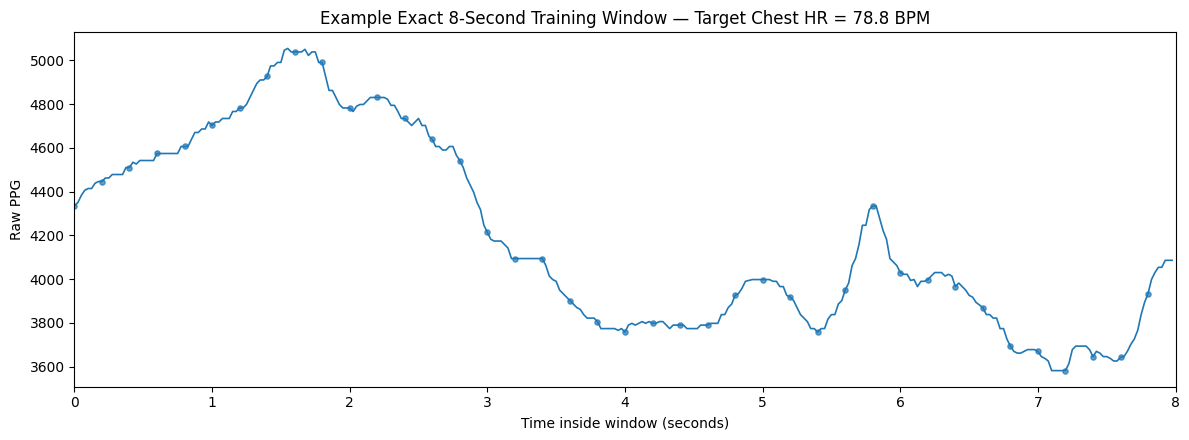

,Activity,Session_ID,Window_ID,Window_Start_ms,Window_End_ms,Window_Duration_sec,Raw_Rows_in_Window,Unique_Selected_Rows,Mean_Time_Error_ms,Max_Time_Error_ms,Chest_Samples,Target_HR_BPM,Split
0,Eating,Eating_01,0,1.790275e+12,1.790275e+12,8.0,363,302,6.1375,38.0,363,78.768593,train


In [20]:
example_index = 0

time_axis = np.linspace(
    0,
    WINDOW_SECONDS,
    MODEL_POINTS,
    endpoint=False
)

example_ppg = (
    X_ppg_train[
        example_index,
        :,
        0
    ]
)

example_hr = float(
    y_train[
        example_index
    ]
)

plt.figure(
    figsize=(12, 4.5)
)

plt.plot(
    time_axis,
    example_ppg,
    linewidth=1.2
)

plt.scatter(
    time_axis[::8],
    example_ppg[::8],
    s=14,
    alpha=0.7
)

plt.title(
    f"Example Exact 8-Second Training Window — "
    f"Target Chest HR = {example_hr:.1f} BPM"
)

plt.xlabel(
    "Time inside window (seconds)"
)

plt.ylabel(
    "Raw PPG"
)

plt.xlim(
    0,
    WINDOW_SECONDS
)

plt.tight_layout()
plt.show()

display(
    meta_train.iloc[
        [example_index]
    ]
)

## 19. No Save Step

This notebook intentionally writes **nothing** to:

- `data/processed/`
- `results/`
- CSV files
- NPZ files
- image files

All model-ready arrays exist only in memory.

Once the preprocessing and model design are finalized, saving will be added once at the end of the project.

## 20. Checks Before PPG-Only Model

Before moving to the first Deep Learning model, confirm:

1. all accepted windows represent exactly **8 seconds**
2. every accepted window has maximum nearest-row timing error ≤ **100 ms**
3. each activity is present in train / validation / test
4. PPG-only shape is `(N, 320, 1)`
5. fusion shape is `(N, 320, 4)`
6. no processed files were created
7. both future models will use exactly the same windows and targets